In [3]:
import os
import warnings

warnings.filterwarnings("ignore")
import MENDER
import scanpy as sc
import pandas as pd
import numpy as np
from sklearn.metrics import *
import matplotlib.pyplot as plt
import scanpy.external as sce

os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ['R_HOME'] = r'C:\Program Files\R\R-4.4.2'
os.environ['R_USER'] = r'C:\Users\CLEARLOVE\.conda\envs\STG\Lib\site-packages\rpy2'

In [4]:
def load_DLPFC(root_dir=r'C:\Code\Data\DLPFC', section_id='151507'):
    # 151507, ..., 151676 12 in total
    ad = sc.read_visium(path=os.path.join(root_dir, section_id), count_file='filtered_feature_bc_matrix.h5',
                        load_images=True)
    ad.var_names_make_unique()

    gt_dir = os.path.join(root_dir, section_id, 'gt')
    gt_df = pd.read_csv(os.path.join(gt_dir, 'tissue_positions_list_GTs.txt'), sep=',', header=None, index_col=0)
    ad.obs['original_clusters'] = gt_df.loc[:, 6]
    keep_bcs = ad.obs.dropna().index
    ad = ad[keep_bcs].copy()
    ad.obs['original_clusters'] = ad.obs['original_clusters'].astype(int).astype(str)
    # print(ad.obs)
    return ad

In [3]:
adata_list = []
# '151507','151508','151509','151510','151669','151670','151671','151672','151673', '151674', '151675', '151676'
section_list = ['151507', '151508', '151509', '151510']

for section_id in section_list:
    input_dir = os.path.join('C:\Code\Data\DLPFC')
    temp_adata = load_DLPFC(root_dir=input_dir, section_id=section_id)
    temp_adata.var_names_make_unique()

    temp_adata = temp_adata[:, [c for c in temp_adata.var_names if 'NegPrb' not in c]].copy()
    temp_adata.obs_names = [x + '_' + section_id for x in temp_adata.obs_names]
    temp_adata.obs['sample'] = pd.Categorical([section_id] * temp_adata.shape[0])
    adata_list.append(temp_adata.copy())

# 直接合并列表中的对象
adata_raw = adata_list[0].concatenate(adata_list[1:])

In [4]:
# input parameters of MENDER
scale = 3
radius = 15

# estimate number of domains
n_cls = 7

adata = adata_raw.copy()
adata.layers['count'] = adata.X.toarray()
sc.pp.filter_genes(adata, min_cells=50)
sc.pp.filter_genes(adata, min_counts=10)
sc.pp.normalize_total(adata, target_sum=1e6)
sc.pp.highly_variable_genes(adata, flavor="seurat_v3", layer='count', n_top_genes=2000)
sc.pp.log1p(adata)

In [5]:
sc.pp.pca(adata)
sce.pp.harmony_integrate(adata, 'batch')
sc.pp.neighbors(adata, use_rep='X_pca_harmony')
sc.tl.umap(adata)

2025-06-13 15:04:42,060 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2025-06-13 15:04:47,053 - harmonypy - INFO - sklearn.KMeans initialization complete.
2025-06-13 15:04:47,161 - harmonypy - INFO - Iteration 1 of 10
2025-06-13 15:04:52,072 - harmonypy - INFO - Iteration 2 of 10
2025-06-13 15:04:56,967 - harmonypy - INFO - Iteration 3 of 10
2025-06-13 15:05:01,912 - harmonypy - INFO - Iteration 4 of 10
2025-06-13 15:05:05,010 - harmonypy - INFO - Iteration 5 of 10
2025-06-13 15:05:07,247 - harmonypy - INFO - Iteration 6 of 10
2025-06-13 15:05:09,024 - harmonypy - INFO - Converged after 6 iterations


In [6]:
# for res in sorted(list(np.arange(0.1, 2.5, 0.01)), reverse=True):
#     sc.tl.leiden(adata, random_state=0, resolution=res)
#     count_unique_leiden = len(pd.DataFrame(adata.obs['leiden']).leiden.unique())
#     if count_unique_leiden == n_cls:
#         break
# print("Best resolution: ", res)

sc.tl.leiden(adata, resolution=1.1399999999999997, key_added='ct', random_state=666)

In [7]:
adata.obs['ct'] = adata.obs['ct'].astype('category')

msm = MENDER.MENDER(
    adata,
    batch_obs='sample',
    # determine which cell state to use
    # we use the cell state got by Leiden
    ct_obs='ct',
    random_seed=0
)

# set the MENDER parameters
msm.prepare()

In [8]:
msm.set_MENDER_para(
    # default of n_scales is 6
    n_scales=scale,
    # for single cell data, nn_mode is set to 'radius'
    nn_mode='ring',
    # default of n_scales is 15 um (see the manuscript for the analysis).
    # MENDER also provide a function 'estimate_radius' for estimating the radius
    nn_para=radius,
)

In [9]:
# construct the context representation
msm.run_representation_mp(
    60
    # the number of processings
)

default number of process is 200


In [10]:
# set the spatial clustering parameter
# positive values for the expected number of domains
# negative values for the clustering resolution
# msm.run_clustering_normal(n_cls)

In [11]:
msm.run_clustering_normal(-0.2)

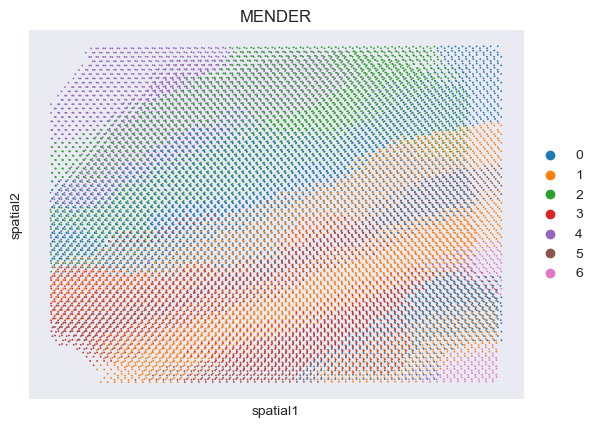

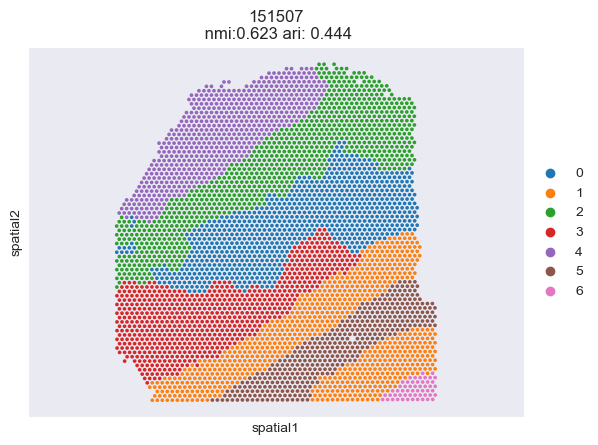

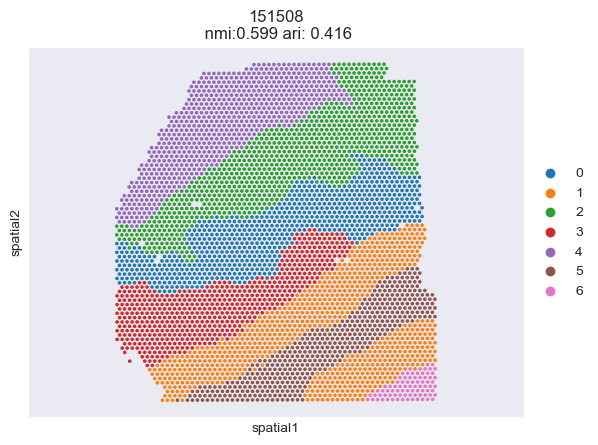

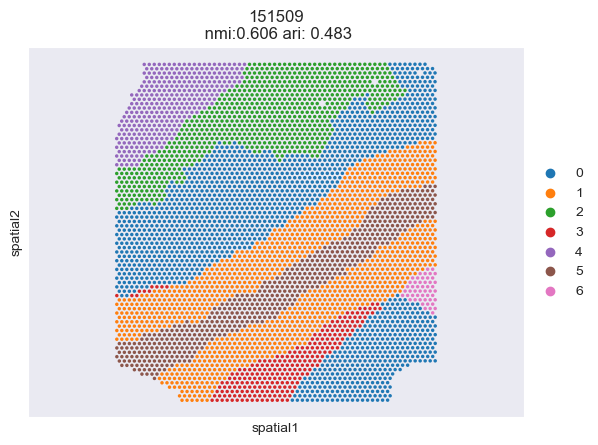

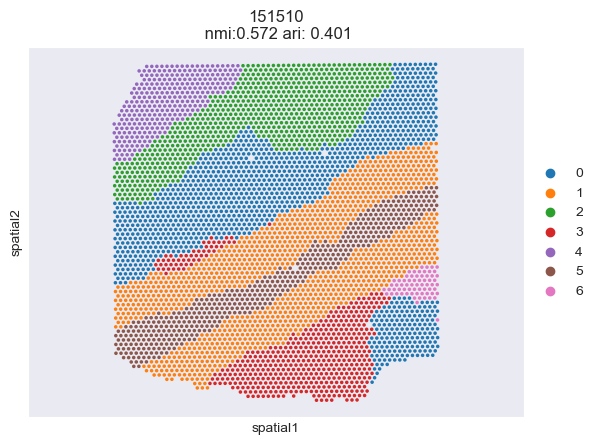

In [12]:
msm.output_cluster_all(obs='MENDER', obs_gt='original_clusters')

In [13]:
file_name = 'MENDER_Donor1.h5ad'
file_path = f'C:\\Code\\Answer\\DLPFC\\{file_name}'
msm.adata_MENDER.write_h5ad(file_path)

In [14]:
adata_list = []
# '151507','151508','151509','151510','151669','151670','151671','151672','151673', '151674', '151675', '151676'
section_list = ['151669','151670','151671','151672']

for section_id in section_list:
    input_dir = os.path.join('C:\Code\Data\DLPFC')
    temp_adata = load_DLPFC(root_dir=input_dir, section_id=section_id)
    temp_adata.var_names_make_unique()

    temp_adata = temp_adata[:, [c for c in temp_adata.var_names if 'NegPrb' not in c]].copy()
    temp_adata.obs_names = [x + '_' + section_id for x in temp_adata.obs_names]
    temp_adata.obs['sample'] = pd.Categorical([section_id] * temp_adata.shape[0])
    adata_list.append(temp_adata.copy())

# 直接合并列表中的对象
adata_raw = adata_list[0].concatenate(adata_list[1:])

# input parameters of MENDER
scale = 3
radius = 15

# estimate number of domains
n_cls = 5

adata = adata_raw.copy()
adata.layers['count'] = adata.X.toarray()
sc.pp.filter_genes(adata, min_cells=50)
sc.pp.filter_genes(adata, min_counts=10)
sc.pp.normalize_total(adata, target_sum=1e6)
sc.pp.highly_variable_genes(adata, flavor="seurat_v3", layer='count', n_top_genes=2000)
sc.pp.log1p(adata)

In [15]:
sc.pp.pca(adata)
sce.pp.harmony_integrate(adata, 'batch')
sc.pp.neighbors(adata, use_rep='X_pca_harmony')
sc.tl.umap(adata)

2025-06-13 15:06:14,262 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2025-06-13 15:06:18,393 - harmonypy - INFO - sklearn.KMeans initialization complete.
2025-06-13 15:06:18,498 - harmonypy - INFO - Iteration 1 of 10
2025-06-13 15:06:22,526 - harmonypy - INFO - Iteration 2 of 10
2025-06-13 15:06:26,536 - harmonypy - INFO - Iteration 3 of 10
2025-06-13 15:06:30,540 - harmonypy - INFO - Iteration 4 of 10
2025-06-13 15:06:34,585 - harmonypy - INFO - Iteration 5 of 10
2025-06-13 15:06:36,049 - harmonypy - INFO - Iteration 6 of 10
2025-06-13 15:06:37,528 - harmonypy - INFO - Iteration 7 of 10
2025-06-13 15:06:39,001 - harmonypy - INFO - Iteration 8 of 10
2025-06-13 15:06:40,456 - harmonypy - INFO - Iteration 9 of 10
2025-06-13 15:06:41,929 - harmonypy - INFO - Iteration 10 of 10
2025-06-13 15:06:43,400 - harmonypy - INFO - Stopped before convergence


In [16]:
# for res in sorted(list(np.arange(0.1, 2.5, 0.01)), reverse=True):
#     sc.tl.leiden(adata, random_state=0, resolution=res)
#     count_unique_leiden = len(pd.DataFrame(adata.obs['leiden']).leiden.unique())
#     if count_unique_leiden == n_cls:
#         break
# print("Best resolution: ", res)

sc.tl.leiden(adata, resolution=0.7699999999999997, key_added='ct', random_state=666)

In [17]:
adata.obs['ct'] = adata.obs['ct'].astype('category')

msm = MENDER.MENDER(
    adata,
    batch_obs='sample',
    # determine which cell state to use
    # we use the cell state got by Leiden
    ct_obs='ct',
    random_seed=0
)

# set the MENDER parameters
msm.prepare()

msm.set_MENDER_para(
    # default of n_scales is 6
    n_scales=scale,
    # for single cell data, nn_mode is set to 'radius'
    nn_mode='ring',
    # default of n_scales is 15 um (see the manuscript for the analysis).
    # MENDER also provide a function 'estimate_radius' for estimating the radius
    nn_para=radius,
)

# construct the context representation
msm.run_representation_mp(
    60
    # the number of processings
)

# set the spatial clustering parameter
# positive values for the expected number of domains
# negative values for the clustering resolution
# msm.run_clustering_normal(n_cls)

default number of process is 200


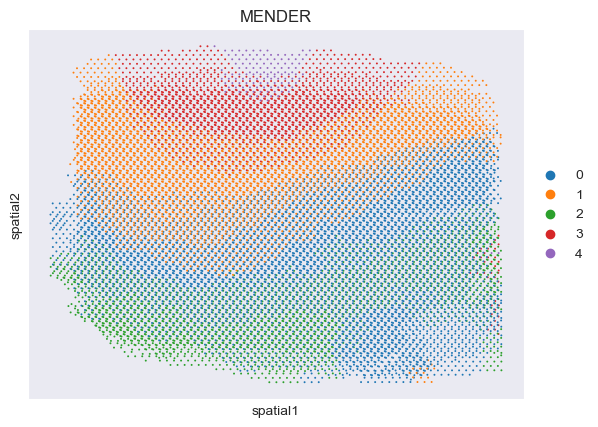

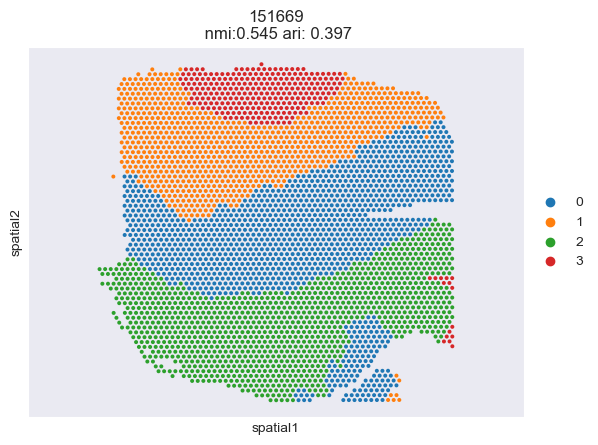

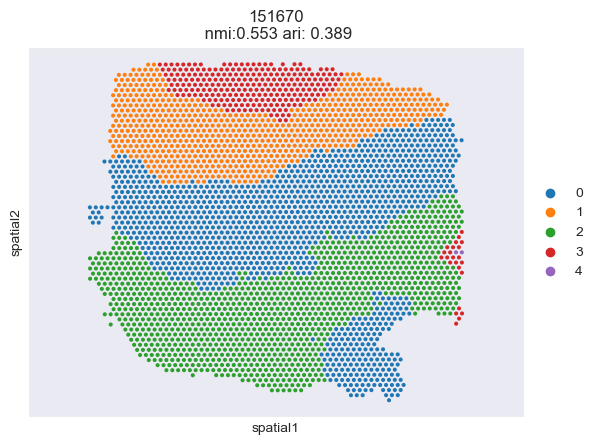

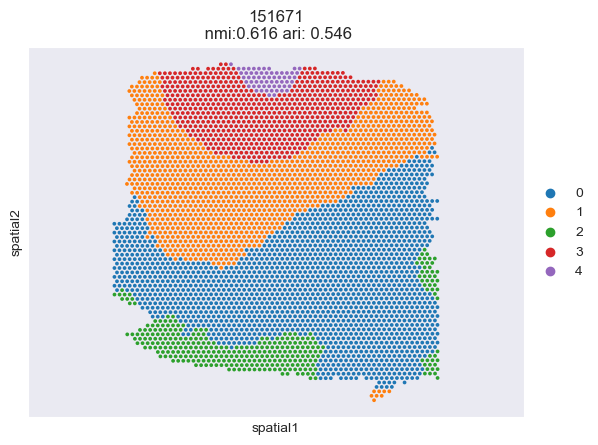

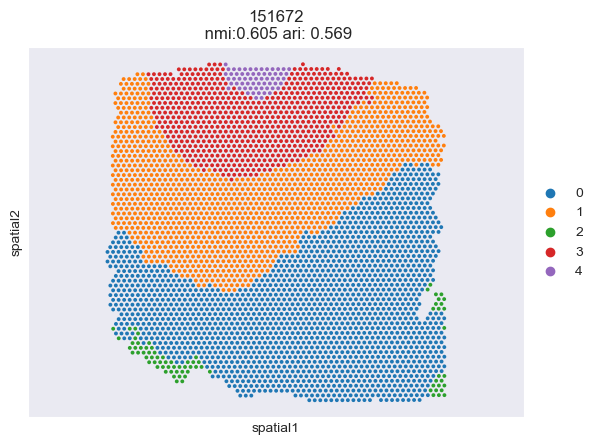

In [18]:
msm.run_clustering_normal(-0.1)

msm.output_cluster_all(obs='MENDER', obs_gt='original_clusters')

In [19]:
file_name = 'MENDER_Donor2.h5ad'
file_path = f'C:\\Code\\Answer\\DLPFC\\{file_name}'
msm.adata_MENDER.write_h5ad(file_path)

In [11]:
adata_list = []
# '151507','151508','151509','151510','151669','151670','151671','151672','151673', '151674', '151675', '151676'
section_list = ['151673', '151674', '151675', '151676']

for section_id in section_list:
    input_dir = os.path.join('C:\Code\Data\DLPFC')
    temp_adata = load_DLPFC(root_dir=input_dir, section_id=section_id)
    temp_adata.var_names_make_unique()

    temp_adata = temp_adata[:, [c for c in temp_adata.var_names if 'NegPrb' not in c]].copy()
    temp_adata.obs_names = [x + '_' + section_id for x in temp_adata.obs_names]
    temp_adata.obs['sample'] = pd.Categorical([section_id] * temp_adata.shape[0])
    adata_list.append(temp_adata.copy())

# 直接合并列表中的对象
adata_raw = adata_list[0].concatenate(adata_list[1:])

# input parameters of MENDER
scale = 3
radius = 12

# estimate number of domains
n_cls = 7

adata = adata_raw.copy()
adata.layers['count'] = adata.X.toarray()
sc.pp.filter_genes(adata, min_cells=50)
sc.pp.filter_genes(adata, min_counts=10)
sc.pp.normalize_total(adata, target_sum=1e6)
sc.pp.highly_variable_genes(adata, flavor="seurat_v3", layer='count', n_top_genes=2000)
sc.pp.log1p(adata)

sc.pp.pca(adata)
sce.pp.harmony_integrate(adata, 'batch')
sc.pp.neighbors(adata, use_rep='X_pca_harmony')
sc.tl.umap(adata)

# for res in sorted(list(np.arange(0.1, 2.5, 0.01)), reverse=True):
#     sc.tl.leiden(adata, random_state=0, resolution=res)
#     count_unique_leiden = len(pd.DataFrame(adata.obs['leiden']).leiden.unique())
#     if count_unique_leiden == n_cls:
#         break
# print("Best resolution: ", res)

sc.tl.leiden(adata, resolution=0.9099999999999996, key_added='ct', random_state=666)

adata.obs['ct'] = adata.obs['ct'].astype('category')

2025-07-16 18:03:46,357 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2025-07-16 18:03:50,534 - harmonypy - INFO - sklearn.KMeans initialization complete.
2025-07-16 18:03:50,619 - harmonypy - INFO - Iteration 1 of 10
2025-07-16 18:03:54,447 - harmonypy - INFO - Iteration 2 of 10
2025-07-16 18:03:58,047 - harmonypy - INFO - Iteration 3 of 10
2025-07-16 18:04:01,573 - harmonypy - INFO - Converged after 3 iterations


default number of process is 200


In [19]:
msm = MENDER.MENDER(
    adata,
    batch_obs='sample',
    # determine which cell state to use
    # we use the cell state got by Leiden
    ct_obs='ct',
    random_seed=0
)

# set the MENDER parameters
msm.prepare()

msm.set_MENDER_para(
    # default of n_scales is 6
    n_scales=scale,
    # for single cell data, nn_mode is set to 'radius'
    nn_mode='ring',
    # default of n_scales is 15 um (see the manuscript for the analysis).
    # MENDER also provide a function 'estimate_radius' for estimating the radius
    nn_para=24,
)

# construct the context representation
msm.run_representation_mp(
    60
    # the number of processings
)

# set the spatial clustering parameter
# positive values for the expected number of domains
# negative values for the clustering resolution
# msm.run_clustering_normal(n_cls)

default number of process is 200


In [20]:
msm.run_clustering_normal(n_cls)

searching resolution to k=7
Res =  0.1 Num of clusters =  7
Recommended res =  0.1


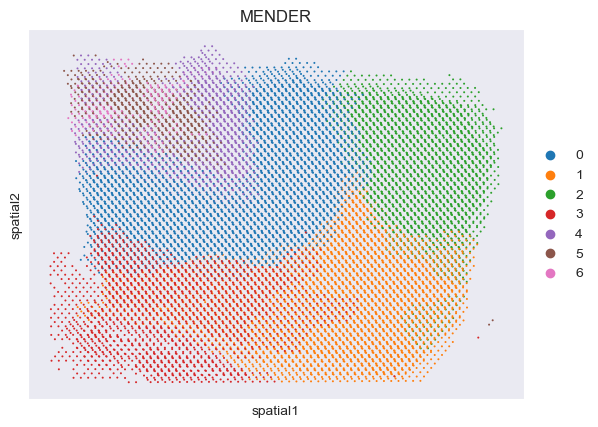

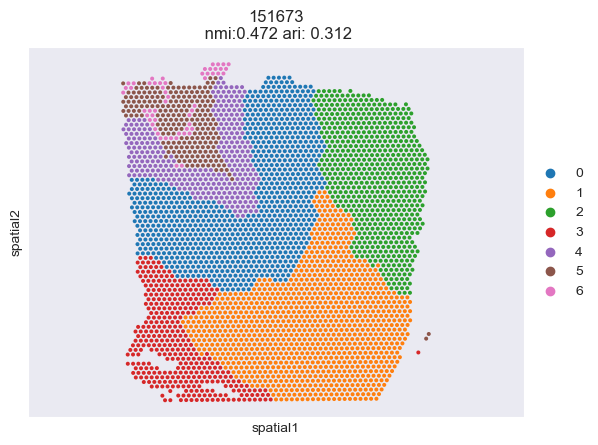

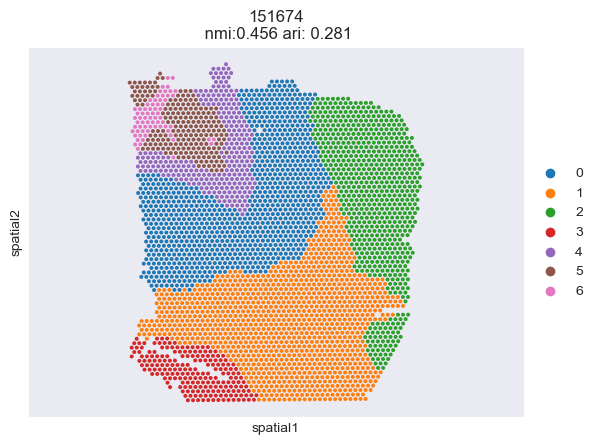

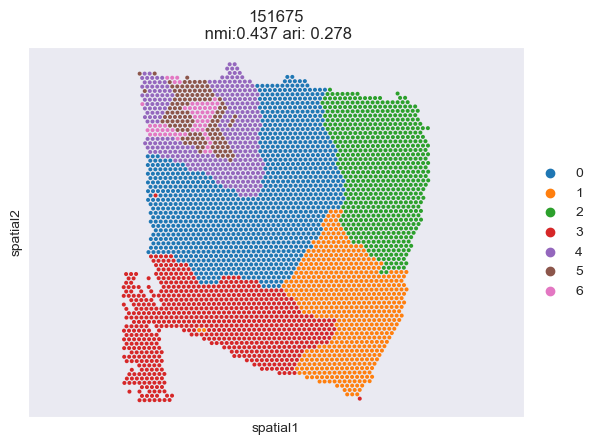

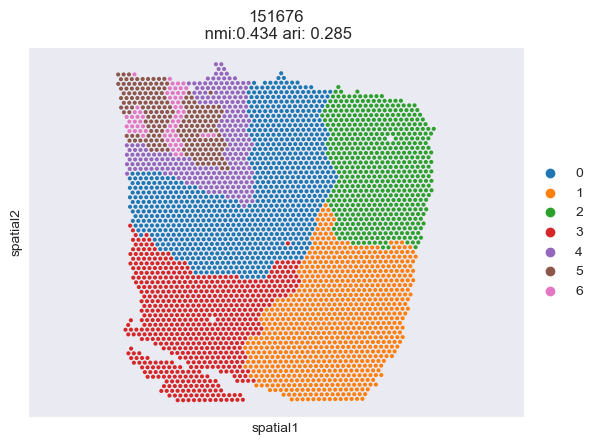

In [21]:
msm.run_clustering_normal(-0.1)

msm.output_cluster_all(obs='MENDER', obs_gt='original_clusters')

In [22]:
file_name = 'MENDER_Donor3.h5ad'
file_path = f'C:\\Code\\Answer\\DLPFC\\{file_name}'
msm.adata_MENDER.write_h5ad(file_path)

In [3]:
adata=sc.read(r'C:\\Code\\Answer\\DLPFC\\MENDER_Donor3.h5ad')
print(adata.obs['MENDER'])

AAACAAGTATCTCCCA-1_151673-0-0    3
AAACAATCTACTAGCA-1_151673-0-0    1
AAACACCAATAACTGC-1_151673-0-0    2
AAACAGAGCGACTCCT-1_151673-0-0    1
AAACAGCTTTCAGAAG-1_151673-0-0    0
                                ..
TTGTTGTGTGTCAAGA-1_151676-3-3    0
TTGTTTCACATCCAGG-1_151676-3-3    2
TTGTTTCATTAGTCTA-1_151676-3-3    4
TTGTTTCCATACAACT-1_151676-3-3    2
TTGTTTGTGTAAATTC-1_151676-3-3    1
Name: MENDER, Length: 14243, dtype: category
Categories (7, object): ['0', '1', '2', '3', '4', '5', '6']
